   # Credit Card Fraud Analytics
   A project on detecting rare fraudulent card payments, like the mobile money and card fraud that banks face in Kenya.

In [1]:
   import warnings
   import numpy as np
   import pandas as pd
   import matplotlib.pyplot as plt
   import seaborn as sns

   warnings.filterwarnings("ignore")
   sns.set_theme(style="whitegrid")

   DATA_PATH = "data/creditcard.csv"

In [2]:
   df = pd.read_csv(DATA_PATH)
   print("Rows and columns:", df.shape)
   df.head()

Rows and columns: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 1. Check the data
Looking for missing values, duplicate rows and unusual numbers before we analyse anything.

In [3]:
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Time span (hours):", round(df["Time"].max() / 3600, 1))
df[["Time", "Amount", "Class"]].describe().T

Missing values: 0
Duplicate rows: 1081
Time span (hours): 48.0


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,94813.859575,47488.145955,0.0,54201.5,84692.0,139320.500,172792.00
Amount,284807.0,88.349619,250.120109,0.0,5.6,22.0,77.165,25691.16
Class,284807.0,0.001727,0.041527,0.0,0.0,0.0,0.000,1.00


In [4]:
print(df.isna().shape)        # (284807, 31) a table
print(df.duplicated().shape)  # (284807,) a single column

(284807, 31)
(284807,)


In [5]:
df[df.duplicated(keep=False)].sort_values("Time").head(6)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
32,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
34,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
112,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
113,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0


In [6]:
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Dropped {n_before - len(df)} duplicate rows -> {len(df):,} transactions remain")

Dropped 1081 duplicate rows -> 283,726 transactions remain


## 2. How rare is fraud?
Counting fraud against legitimate payments. If fraud is very rare, a model can look accurate while catching almost none of it.

Legitimate: 283,253
Fraud:      473
Fraud rate: 0.167%
About 1 fraud in every 600 transactions


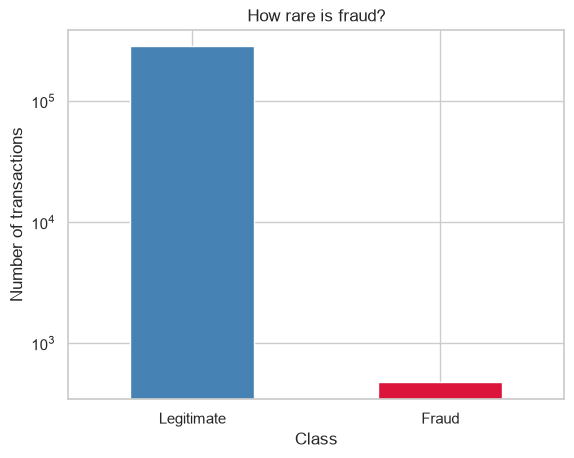

In [7]:
counts = df["Class"].value_counts()
fraud_rate = counts[1] / len(df) * 100

print(f"Legitimate: {counts[0]:,}")
print(f"Fraud:      {counts[1]:,}")
print(f"Fraud rate: {fraud_rate:.3f}%")
print(f"About 1 fraud in every {len(df) / counts[1]:.0f} transactions")

ax = counts.rename({0: "Legitimate", 1: "Fraud"}).plot(kind="bar", color=["steelblue", "crimson"])
ax.set_title("How rare is fraud?")
ax.set_ylabel("Number of transactions")
plt.xticks(rotation=0)
ax.set_yscale("log")
plt.show()

## 3. Do fraud payments look different?
Comparing the amounts of fraud and legitimate payments to see if fraud has a pattern.

In [8]:
df.groupby("Class")["Amount"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,283253.0,88.41,250.38,0.0,5.67,22.00,77.46,25691.16
1,473.0,123.87,260.21,0.0,1.00,9.82,105.89,2125.87


**What we see:** fraud payments are usually small (middle value about 10 vs 22 for normal payments), but a few large ones raise the average. Amount alone does not separate fraud from normal payments.

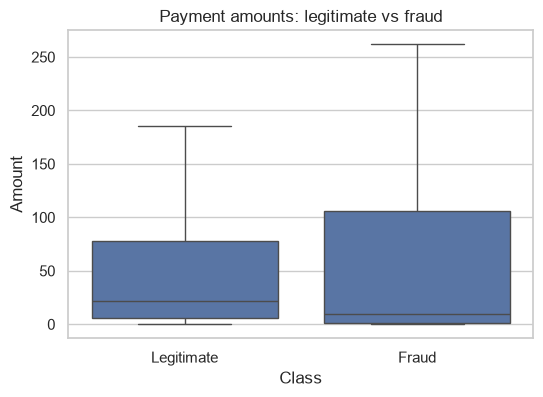

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=df, x="Class", y="Amount", showfliers=False, ax=ax)
ax.set_xticklabels(["Legitimate", "Fraud"])
ax.set_title("Payment amounts: legitimate vs fraud")
ax.set_ylabel("Amount")
plt.show()

## 4. Does fraud happen more at certain hours?
Turning the Time column into an hour-of-day and comparing the fraud rate across hours.

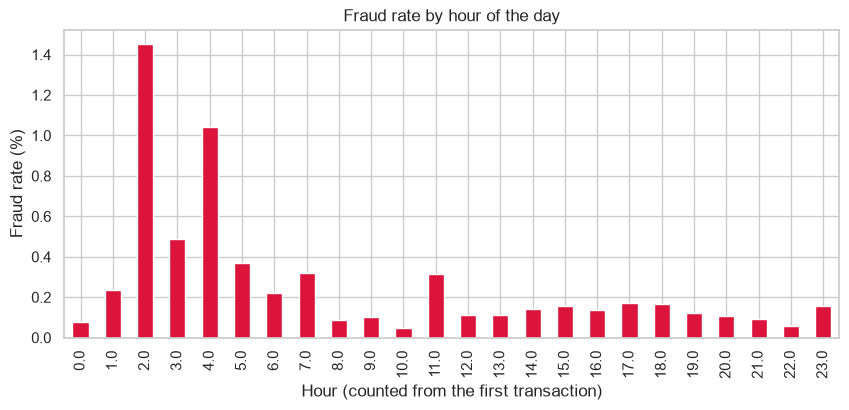

Hour
2.0    1.45
4.0    1.04
3.0    0.49
Name: Class, dtype: float64


In [10]:
df["Hour"] = (df["Time"] // 3600) % 24
fraud_by_hour = df.groupby("Hour")["Class"].mean() * 100

ax = fraud_by_hour.plot(kind="bar", figsize=(10, 4), color="crimson")
ax.set_title("Fraud rate by hour of the day")
ax.set_xlabel("Hour (counted from the first transaction)")
ax.set_ylabel("Fraud rate (%)")
plt.show()

print(fraud_by_hour.sort_values(ascending=False).head(3).round(2))

In [11]:
import os
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve,
                             precision_recall_curve, ConfusionMatrixDisplay)
from sklearn.utils import resample
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42        
COST_PER_REVIEW = 5.0   
FIG_DIR = "reports/figures"
os.makedirs(FIG_DIR, exist_ok=True)

def savefig(name):
    """Show the chart and also save it as a PNG file in reports/figures."""
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 5. Statistical tests
Checking whether the differences we saw are real or just chance.

In [12]:
# Is the payment amount different for fraud? (Mann-Whitney test)
fraud_amt = df.loc[df["Class"] == 1, "Amount"]
legit_amt = df.loc[df["Class"] == 0, "Amount"]
u, p_amount = stats.mannwhitneyu(fraud_amt, legit_amt, alternative="two-sided")
print(f"Amount, fraud vs legitimate: p-value = {p_amount:.2e}")
print(f"Median amount -> fraud: {fraud_amt.median():.2f} | legitimate: {legit_amt.median():.2f}")

# Is the fraud rate different across hours? (Chi-square test)
chi2, p_hour, _, _ = stats.chi2_contingency(pd.crosstab(df["Hour"], df["Class"]))
print(f"Hour vs fraud: p-value = {p_hour:.2e}")

Amount, fraud vs legitimate: p-value = 2.69e-05
Median amount -> fraud: 9.82 | legitimate: 22.00
Hour vs fraud: p-value = 3.09e-101


**How to read a p-value:** below 0.05 means the difference is unlikely to be pure chance. Above 0.05 means we cannot say the difference is real.

## 6. Which features separate fraud best?
For each anonymised column V1 to V28 we measure how different its values are for fraud and legitimate payments (the KS statistic: 0 means identical, 1 means completely different).

Most fraud-revealing features: ['V14', 'V10', 'V12', 'V4', 'V11', 'V17', 'V3', 'V16']


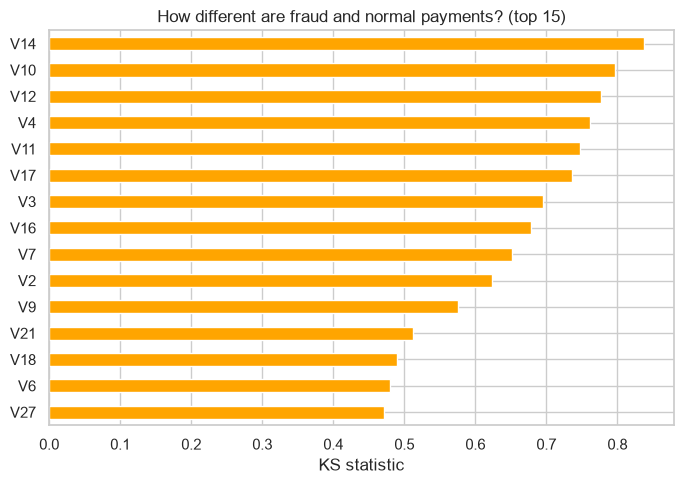

In [13]:
v_cols = [c for c in df.columns if c.startswith("V")]
ks = pd.Series({c: stats.ks_2samp(df.loc[df["Class"] == 1, c],
                                  df.loc[df["Class"] == 0, c]).statistic for c in v_cols})
ks = ks.sort_values(ascending=False)
print("Most fraud-revealing features:", ks.head(8).index.tolist())

ks.head(15).sort_values().plot.barh(figsize=(7, 5), color="orange")
plt.title("How different are fraud and normal payments? (top 15)")
plt.xlabel("KS statistic")
savefig("04_feature_separation")

## 7. Preparing the data and splitting it
Splitting into train (60%), validation (20%) and test (20%) with the same fraud share in each part.

In [14]:
X = df.drop(columns=["Class", "Time", "Hour"]).copy()   # the inputs
X["Amount_log"] = np.log1p(X.pop("Amount"))              # squash the huge amounts
X["Hour_sin"] = np.sin(2 * np.pi * df["Hour"] / 24)      # hour as a circle, so 23h and 0h are close
X["Hour_cos"] = np.cos(2 * np.pi * df["Hour"] / 24)
y = df["Class"]                                          # the answer we want to predict
amount_raw = df["Amount"]                                # real amounts, kept for the cost analysis

# first cut off 20% for the final test, then 25% of the rest (= 20% overall) for validation
X_tr_full, X_test, y_tr_full, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_tr_full, y_tr_full, test_size=0.25, stratify=y_tr_full, random_state=RANDOM_STATE)

# scale Amount using the training data only
scaler = RobustScaler().fit(X_train[["Amount_log"]])
for part in (X_train, X_val, X_test):
    part["Amount_log"] = scaler.transform(part[["Amount_log"]]).ravel()

for name, labels in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{name:<11} rows={len(labels):>7,}  frauds={int(labels.sum()):>4}  fraud rate={labels.mean() * 100:.3f}%")

train       rows=170,235  frauds= 284  fraud rate=0.167%
validation  rows= 56,745  frauds=  94  fraud rate=0.166%
test        rows= 56,746  frauds=  95  fraud rate=0.167%


## 8. Handling the imbalance
Fraud is so rare that a model can ignore it. We try four ways of dealing with that, on the training data only:
**none**, **class_weight** (fraud mistakes count more), **undersample** (drop many legitimate rows) and **oversample** (repeat fraud rows).

In [15]:
def rebalance(X_, y_, strategy, seed=RANDOM_STATE):
    """Return a rebalanced copy of the TRAINING data."""
    if strategy in ("none", "class_weight"):
        return X_, y_
    pos, neg = X_[y_ == 1], X_[y_ == 0]
    if strategy == "undersample":
        neg = resample(neg, replace=False, n_samples=min(len(neg), 10 * len(pos)), random_state=seed)
    elif strategy == "oversample":
        pos = resample(pos, replace=True, n_samples=max(len(pos), len(neg) // 10), random_state=seed)
    else:
        raise ValueError(strategy)
    Xr = pd.concat([pos, neg])
    yr = pd.Series([1] * len(pos) + [0] * len(neg), index=Xr.index)
    order = np.random.RandomState(seed).permutation(len(Xr))
    return Xr.iloc[order], yr.iloc[order]

for strategy in ["none", "undersample", "oversample"]:
    Xr, yr = rebalance(X_train, y_train, strategy)
    print(f"{strategy:<12} rows={len(yr):>8,}  frauds={int(yr.sum()):>6,}")

none         rows= 170,235  frauds=   284
undersample  rows=   3,124  frauds=   284
oversample   rows= 186,946  frauds=16,995


## 9. Training the models
Three models: **Logistic Regression** (simple baseline), **Random Forest** and **Gradient Boosting** (stronger, can find complicated patterns). Each is paired with different imbalance strategies.

In [16]:
def make_model(kind, strategy):
    weight = "balanced" if strategy == "class_weight" else None
    if kind == "LogReg":
        return LogisticRegression(max_iter=2000, class_weight=weight)
    if kind == "RandForest":
        return RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=3, n_jobs=-1,
                                      class_weight="balanced_subsample" if weight else None,
                                      random_state=RANDOM_STATE)
    if kind == "HistGB":
        return HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, class_weight=weight,
                                              random_state=RANDOM_STATE)

experiments = [("LogReg", "none"), ("LogReg", "class_weight"), ("LogReg", "undersample"),
               ("RandForest", "class_weight"), ("RandForest", "undersample"),
               ("HistGB", "none"), ("HistGB", "class_weight"), ("HistGB", "oversample")]

fitted, val_proba, test_proba = {}, {}, {}
for kind, strategy in experiments:
    name = f"{kind} | {strategy}"
    Xr, yr = rebalance(X_train, y_train, strategy)
    model = make_model(kind, strategy).fit(Xr, yr)
    fitted[name] = model
    val_proba[name] = model.predict_proba(X_val)[:, 1]    # fraud probability on validation data
    test_proba[name] = model.predict_proba(X_test)[:, 1]  # fraud probability on test data
    print(f"trained {name}")

trained LogReg | none
trained LogReg | class_weight
trained LogReg | undersample
trained RandForest | class_weight
trained RandForest | undersample
trained HistGB | none
trained HistGB | class_weight
trained HistGB | oversample


## 10. Evaluating the models
We pick the best model using the **validation** data, then report on the untouched **test** data.
**Precision:** of the payments flagged as fraud, how many really were. **Recall:** of all real fraud, how much we caught. **F1:** a balance of the two. **PR-AUC:** one score for how well fraud is ranked above normal payments (best for rare events).

In [17]:
def metrics(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {"Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred),
            "F1": f1_score(y_true, pred),
            "ROC-AUC": roc_auc_score(y_true, proba),
            "PR-AUC": average_precision_score(y_true, proba)}

val_pr = pd.Series({n: average_precision_score(y_val, p) for n, p in val_proba.items()})
val_pr = val_pr.sort_values(ascending=False)

results = pd.DataFrame({n: metrics(y_test, p) for n, p in test_proba.items()}).T
results["Val PR-AUC"] = val_pr
results = results.sort_values("Val PR-AUC", ascending=False)
display(results.round(4))

best_name = val_pr.index[0]
print("Best model (by validation PR-AUC):", best_name)
results.round(4).to_csv("reports/model_comparison_test.csv")

,Precision,Recall,F1,ROC-AUC,PR-AUC,Val PR-AUC
HistGB | oversample,0.9000,0.7579,0.8229,0.9693,0.7996,0.8896
RandForest | class_weight,0.9079,0.7263,0.8070,0.9627,0.7996,0.8638
RandForest | undersample,0.5556,0.7895,0.6522,0.9631,0.7530,0.8068
LogReg | none,0.8507,0.6000,0.7037,0.9532,0.6975,0.8011
LogReg | class_weight,0.0495,0.8737,0.0936,0.9626,0.6803,0.7899
HistGB | class_weight,0.4326,0.8105,0.5641,0.9496,0.7107,0.7755
LogReg | undersample,0.3068,0.8105,0.4451,0.9555,0.6161,0.7737
HistGB | none,0.6667,0.7158,0.6904,0.8630,0.5814,0.6200


Best model (by validation PR-AUC): HistGB | oversample


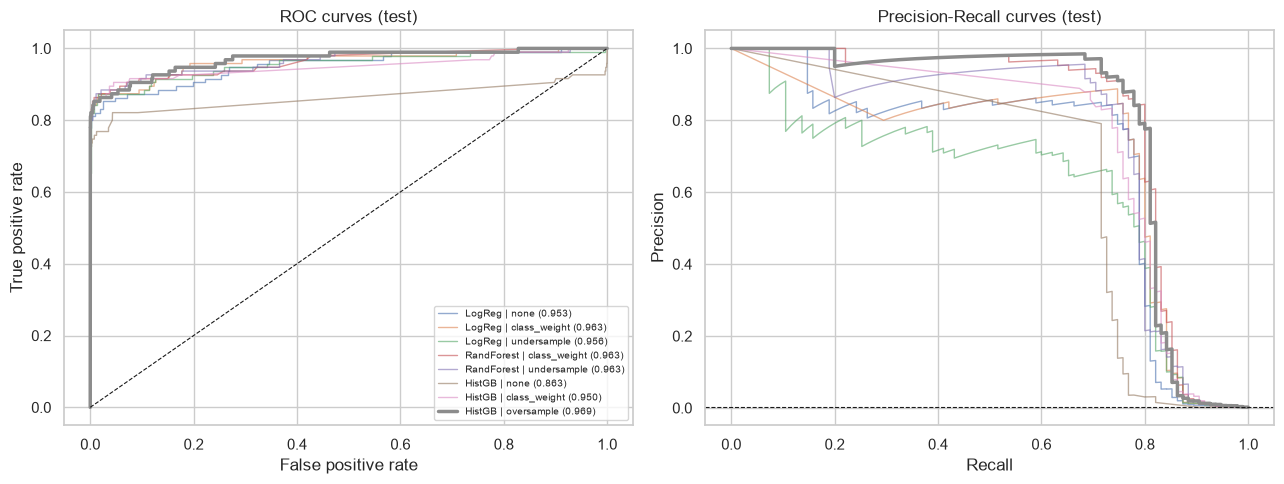

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for n, p in test_proba.items():
    is_best = (n == best_name)
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=f"{n} ({roc_auc_score(y_test, p):.3f})",
               lw=2.5 if is_best else 1, alpha=1 if is_best else 0.6)
    prec, rec, _ = precision_recall_curve(y_test, p)
    ax[1].plot(rec, prec, lw=2.5 if is_best else 1, alpha=1 if is_best else 0.6)
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[0].set_title("ROC curves (test)"); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
ax[0].legend(fontsize=7, loc="lower right")
ax[1].axhline(y_test.mean(), color="k", ls="--", lw=0.8)
ax[1].set_title("Precision-Recall curves (test)"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
savefig("05_roc_pr_curves")

## 11. Choosing the alert threshold
A model gives each payment a fraud probability. The usual cut-off of 0.5 is arbitrary, so we pick the cut-off with the lowest **total cost** on the validation data:
a missed fraud costs the payment amount, and a false alarm costs `COST_PER_REVIEW`.

Best threshold for HistGB | oversample: 0.46  (the default would be 0.50)


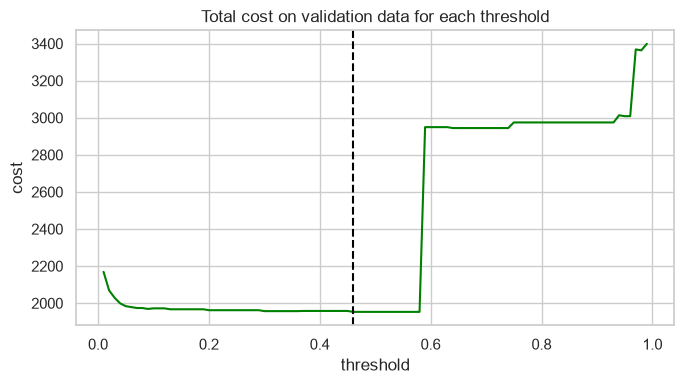

In [19]:
def total_cost(proba, labels, amounts, threshold):
    flagged = proba >= threshold
    missed_fraud_loss = amounts[(~flagged) & (labels == 1)].sum()
    false_alarm_cost = COST_PER_REVIEW * ((flagged) & (labels == 0)).sum()
    return missed_fraud_loss + false_alarm_cost

amt_val = amount_raw.loc[X_val.index].values
amt_test = amount_raw.loc[X_test.index].values
yv, yt = y_val.values, y_test.values

thresholds = np.linspace(0.01, 0.99, 99)
val_costs = np.array([total_cost(val_proba[best_name], yv, amt_val, t) for t in thresholds])
best_thr = float(thresholds[val_costs.argmin()])
print(f"Best threshold for {best_name}: {best_thr:.2f}  (the default would be 0.50)")

plt.figure(figsize=(7, 4))
plt.plot(thresholds, val_costs, color="green")
plt.axvline(best_thr, color="black", ls="--")
plt.title("Total cost on validation data for each threshold")
plt.xlabel("threshold"); plt.ylabel("cost")
savefig("06_threshold_cost")

## 12. What does the model save?
Final check on the **test** data, comparing: no model, the default threshold of 0.50, and our tuned threshold.

In [20]:
def business_table(proba, policies):
    fraud_value = amt_test[yt == 1].sum()
    rows = {"No model (approve everything)": {"Fraud caught": 0, "Frauds missed": int(yt.sum()),
            "False alarms": 0, "Fraud value lost": fraud_value, "Review cost": 0.0, "Total cost": fraud_value}}
    for label, thr in policies.items():
        flagged = proba >= thr
        caught = int((flagged & (yt == 1)).sum())
        missed = int((~flagged & (yt == 1)).sum())
        false_alarms = int((flagged & (yt == 0)).sum())
        lost = amt_test[(~flagged) & (yt == 1)].sum()
        review = COST_PER_REVIEW * false_alarms
        rows[label] = {"Fraud caught": caught, "Frauds missed": missed, "False alarms": false_alarms,
                       "Fraud value lost": lost, "Review cost": review, "Total cost": lost + review}
    table = pd.DataFrame(rows).T
    table["Savings vs no model"] = fraud_value - table["Total cost"]
    return table

biz = business_table(test_proba[best_name], {"Model at 0.50": 0.5, f"Model at tuned {best_thr:.2f}": best_thr})
display(biz.round(2))
biz.round(2).to_csv("reports/business_impact.csv")

tuned_pred = (test_proba[best_name] >= best_thr).astype(int)
print(f"Tuned model on test data -> precision {precision_score(yt, tuned_pred):.3f}, "
      f"recall {recall_score(yt, tuned_pred):.3f}, F1 {f1_score(yt, tuned_pred):.3f}")

,Fraud caught,Frauds missed,False alarms,Fraud value lost,Review cost,Total cost,Savings vs no model
No model (approve everything),0.0,95.0,0.0,14766.31,0.0,14766.31,0.00
Model at 0.50,72.0,23.0,8.0,3812.28,40.0,3852.28,10914.03
Model at tuned 0.46,72.0,23.0,8.0,3812.28,40.0,3852.28,10914.03


Tuned model on test data -> precision 0.900, recall 0.758, F1 0.823


**Reading the trade-off:** a missed fraud (false negative) costs the full payment amount, while a false alarm (false positive) costs analyst time and an annoyed customer. Because missed fraud usually costs more, the best threshold is often below 0.5. Try changing `COST_PER_REVIEW` in the Step 12 cell and re-running from Step 19 to see how the decision changes.

## 13. What drives the model's decisions?
Shuffling one column at a time and seeing how much the model gets worse (permutation importance). A bigger drop means that column matters more.

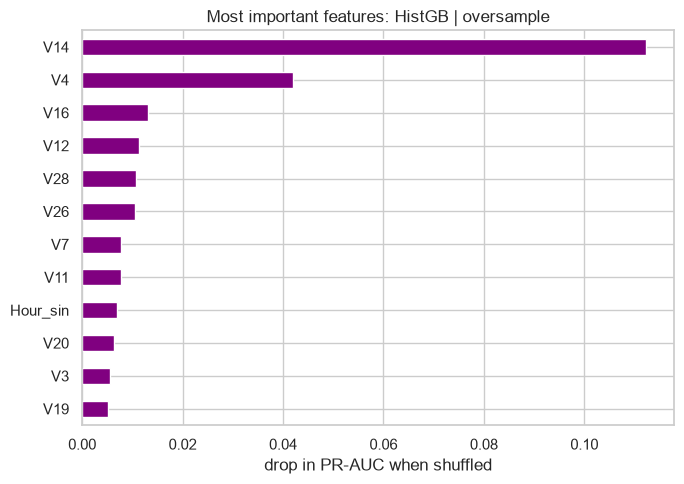

In [21]:
best_model = fitted[best_name]
pi = permutation_importance(best_model, X_test, y_test, scoring="average_precision",
                            n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)

imp.head(12).sort_values().plot.barh(figsize=(7, 5), color="purple")
plt.title(f"Most important features: {best_name}")
plt.xlabel("drop in PR-AUC when shuffled")
savefig("07_feature_importance")

## 14. One-page dashboard and key findings

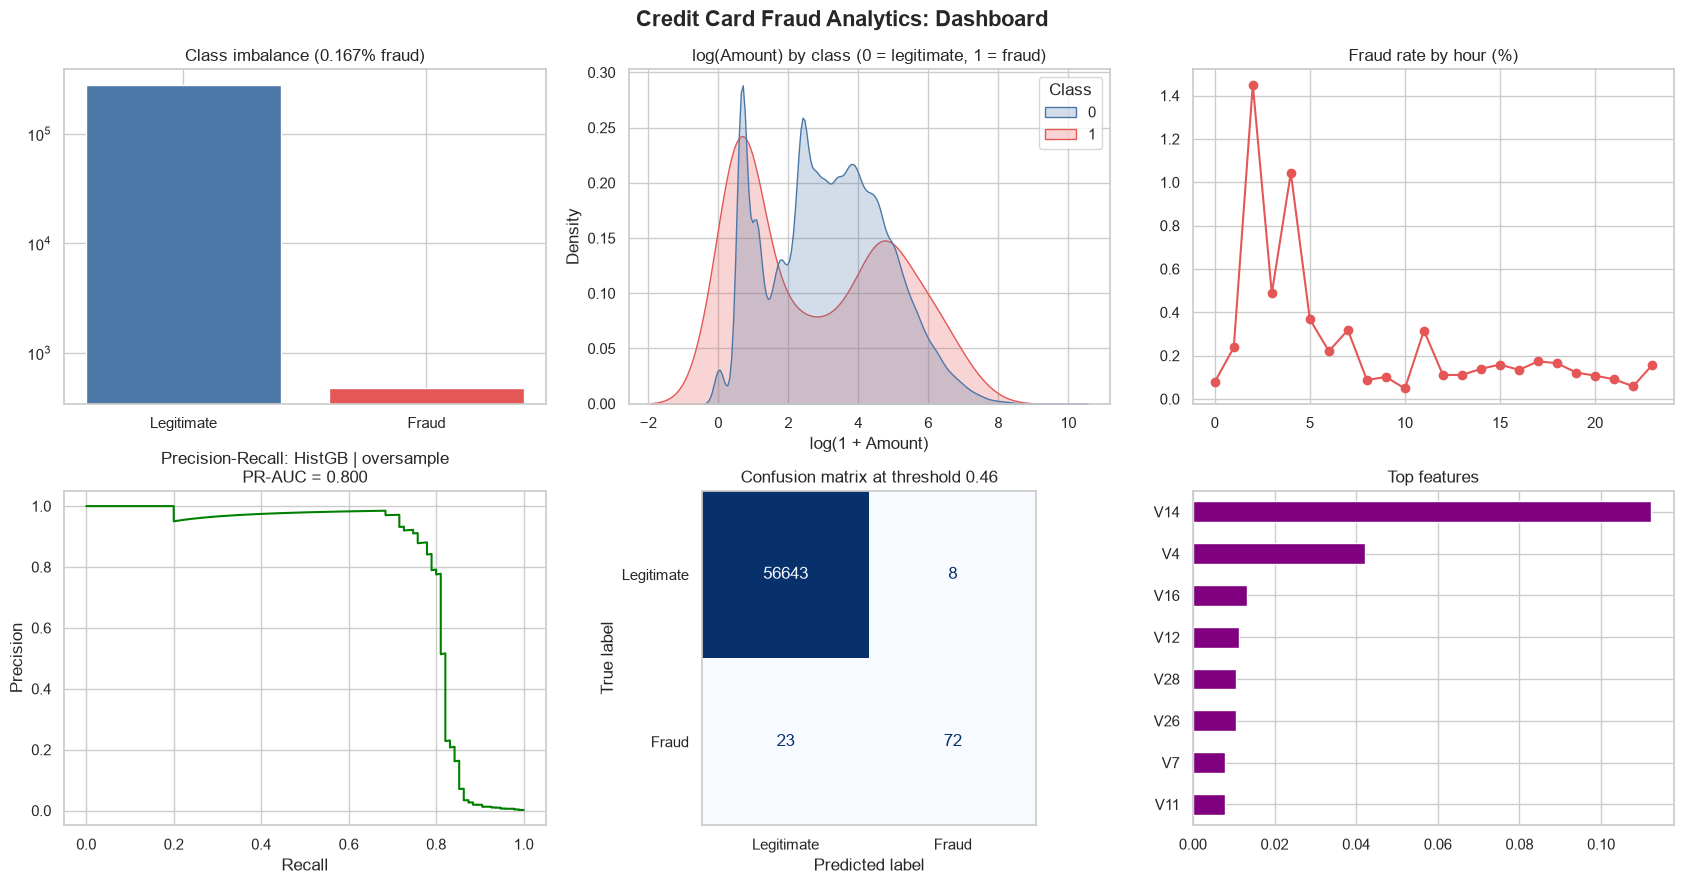

In [22]:
counts = df["Class"].value_counts().sort_index()
pct = counts / counts.sum() * 100

fig = plt.figure(figsize=(17, 9))
grid = fig.add_gridspec(2, 3)

ax = fig.add_subplot(grid[0, 0])
ax.bar(["Legitimate", "Fraud"], counts.values, color=["#4C78A8", "#E45756"])
ax.set_yscale("log"); ax.set_title(f"Class imbalance ({pct[1]:.3f}% fraud)")

ax = fig.add_subplot(grid[0, 1])
sns.kdeplot(data=df, x=np.log1p(df["Amount"]), hue="Class", common_norm=False, fill=True,
            palette={0: "#4C78A8", 1: "#E45756"}, ax=ax)
ax.set_title("log(Amount) by class (0 = legitimate, 1 = fraud)")
ax.set_xlabel("log(1 + Amount)")

ax = fig.add_subplot(grid[0, 2])
ax.plot(fraud_by_hour.index, fraud_by_hour.values, marker="o", color="#E45756")
ax.set_title("Fraud rate by hour (%)")

ax = fig.add_subplot(grid[1, 0])
prec, rec, _ = precision_recall_curve(y_test, test_proba[best_name])
ax.plot(rec, prec, color="green")
ax.set_title(f"Precision-Recall: {best_name}\nPR-AUC = {average_precision_score(y_test, test_proba[best_name]):.3f}")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")

ax = fig.add_subplot(grid[1, 1])
ConfusionMatrixDisplay(confusion_matrix(yt, tuned_pred), display_labels=["Legitimate", "Fraud"]).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title(f"Confusion matrix at threshold {best_thr:.2f}")
ax.grid(False)

ax = fig.add_subplot(grid[1, 2])
imp.head(8).sort_values().plot.barh(ax=ax, color="purple")
ax.set_title("Top features")

fig.suptitle("Credit Card Fraud Analytics: Dashboard", fontsize=16, fontweight="bold")
savefig("00_dashboard")

In [23]:
tn, fp, fn, tp = confusion_matrix(yt, tuned_pred).ravel()
tuned_row = biz.iloc[-1]
no_model_cost = biz.iloc[0]["Total cost"]

print(f"""
KEY FINDINGS (test data, model = {best_name}, threshold = {best_thr:.2f})
1. Fraud is {pct[1]:.3f}% of payments (1 in {counts[0] / counts[1]:.0f}), so accuracy alone is meaningless.
2. Best model: PR-AUC = {average_precision_score(y_test, test_proba[best_name]):.3f}, ROC-AUC = {roc_auc_score(y_test, test_proba[best_name]):.3f}.
3. It catches {tp} of {tp + fn} frauds (recall {tp / (tp + fn):.1%}) with precision {tp / max(tp + fp, 1):.1%}; {fp} genuine payments were flagged.
4. Estimated cost with the model: {tuned_row['Total cost']:,.0f} against {no_model_cost:,.0f} with no model
   (saving {tuned_row['Savings vs no model']:,.0f}, assuming {COST_PER_REVIEW} per review).
5. Most influential features: {', '.join(imp.head(3).index)}.
""")


KEY FINDINGS (test data, model = HistGB | oversample, threshold = 0.46)
1. Fraud is 0.167% of payments (1 in 599), so accuracy alone is meaningless.
2. Best model: PR-AUC = 0.800, ROC-AUC = 0.969.
3. It catches 72 of 95 frauds (recall 75.8%) with precision 90.0%; 8 genuine payments were flagged.
4. Estimated cost with the model: 3,852 against 14,766 with no model
   (saving 10,914, assuming 5.0 per review).
5. Most influential features: V14, V4, V16.



## Conclusions and recommendations
1. **Judge fraud models by PR-AUC and recall, not accuracy.** Fraud is a rare-event problem.
2. **Deal with the imbalance on purpose.** Compare the strategies in Section 10. Resampling is done on training data only.
3. **Set the alert threshold from business costs**, not the default 0.5, and re-tune it when costs or fraud patterns change.
4. **Use risk tiers:** approve low scores automatically, ask for an OTP on medium scores, and block with manual review on the highest scores. This limits friction for genuine customers.
5. **Monitor and retrain.** Fraud patterns change quickly, so track recall, precision and score distribution regularly.

**Limitations.** The V columns are anonymised, so we cannot explain them in business terms. The data covers only two days of European card payments, not Kenyan data. A random split was used, whereas a real system should be tested on later time periods. Costs are assumptions.